# TV1: Exploratory Data Analysis & RFM Preprocessing

**CO3029, đề tài 03.** Phân tích toàn bộ Online Retail II trước khi gom cụm khách hàng.

Notebook dùng **cả hai sheet**, các biểu đồ có số liệu từ file thực, và gọi lại chính các hàm trong `preprocessing/preprocess.py` nhằm tránh sai lệch giữa báo cáo với pipeline. Đường dẫn dữ liệu: `data/raw/online_retail_II.xlsx`.

**Quy ước:** Tập gốc dùng cho EDA; giao dịch hợp lệ chỉ dùng sau khi đã loại mã khách rỗng, trùng, mã phi sản phẩm và tách hủy. `CancelRate` vẫn đếm hóa đơn hủy phân biệt. Không diễn giải lượng âm là giao dịch mua.

## 1. Khởi tạo và kiểm tra đường dẫn

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
if ROOT.name == "preprocessing":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from preprocessing.preprocess import (
    RAW_COLUMNS, FEATURE_COLUMNS, SHEETS, describe_raw,
    load_retail_data, clean_transactions, get_reference_date,
    build_customer_features, feature_statistics, find_high_correlations,
    log_transform_features, run_pipeline_from_frame, transform_features,
)
from preprocessing.eda_utils import make_eda_outputs
from reports.generate_report import generate_report

DATA_FILE = ROOT / "data" / "raw" / "online_retail_II.xlsx"
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Khong tim thay {DATA_FILE}. Chay: python -m preprocessing.download_data "
        "hoac tai Online Retail II tu UCI, sau do restart & run all."
    )
print("Root:", ROOT)
print("Input:", DATA_FILE)


Root: C:\Users\Lenovo\Downloads\BTL_DATAMINING
Input: C:\Users\Lenovo\Downloads\BTL_DATAMINING\data\raw\online_retail_II.xlsx


## 2. Đọc đầy đủ hai sheet, mô tả quy mô dữ liệu

In [2]:
CACHE_DIR = ROOT / "data" / "processed"
CACHE_READY = all((ROOT / path).exists() for path in (
    "data/processed/pipeline_metadata.json", "data/processed/eda_observations.json",
    "data/processed/cleaning_audit.csv", "data/processed/customers_features.csv",
    "data/processed/X_scaled.csv", "models/scaler.joblib",
    "preprocessing/figures/07_correlation_spearman.png",
))
if CACHE_READY:
    raw = None
    raw_summary = json.loads((CACHE_DIR / "pipeline_metadata.json").read_text(encoding="utf-8"))
    display(Markdown("**Chế độ:** dùng EDA đã lưu từ workbook gốc. Có thể xóa cache rồi Run All để chạy lại dữ liệu thô."))
else:
    raw = load_retail_data(DATA_FILE)  # both UCI workbook sheets
    raw_summary = describe_raw(raw)
    display(Markdown("**Chế độ:** đọc lại 2 sheet gốc để tính kết quả từ đầu."))
summary_table = pd.DataFrame({
    "Chi so": ["Rows", "Invoices", "Customers with ID", "Stock codes", "Countries", "Date from", "Date to"],
    "Gia tri": [raw_summary["raw_rows"], raw_summary["unique_invoices"],
                raw_summary["unique_customers"], raw_summary["unique_products"],
                raw_summary["unique_countries"], raw_summary["date_min"], raw_summary["date_max"]],
})
if raw is not None:
    display(raw.groupby("SourceSheet", as_index=False).size().rename(columns={"size":"Rows"}))
    display(raw.loc[:, RAW_COLUMNS].head())
else:
    display(pd.DataFrame(raw_summary["sheet_rows"].items(), columns=["SourceSheet", "Rows"]))
display(summary_table)


**Chế độ:** dùng EDA đã lưu từ workbook gốc. Có thể xóa cache rồi Run All để chạy lại dữ liệu thô.

,SourceSheet,Rows
0,Year 2010-2011,541910
1,Year 2009-2010,525461


,Chi so,Gia tri
0,Rows,1067371
1,Invoices,53628
2,Customers with ID,5942
3,Stock codes,5304
4,Countries,43
5,Date from,2009-12-01 07:45:00
6,Date to,2011-12-09 12:50:00


**Nhận xét:** Mỗi dòng là một mặt hàng trong hóa đơn. `Invoice.nunique()` khác số dòng; `Customer ID.nunique()` mặc định bỏ giá trị thiếu. Cần tổng hợp theo khách hàng trước khi áp dụng mô hình phân cụm.

## 3. Tỷ lệ thiếu và ảnh hưởng đến RFM

In [3]:
missing = pd.DataFrame(raw_summary["missing"]).T
missing.columns = ["Missing rows", "Missing %"]
display(missing.sort_values("Missing %", ascending=False))
display(Markdown(
    f"**Nhận xét dữ liệu:** Customer ID thiếu **{missing.loc['Customer ID','Missing rows']:,}** dòng "
    f"({missing.loc['Customer ID','Missing %']:.2f}%), "
    f"Description thiếu **{missing.loc['Description','Missing rows']:,}** dòng. "
    "Không điền Customer ID giả vì sẽ trộn giao dịch của nhiều người."
))


,Missing rows,Missing %
Customer ID,243007.0,22.7669
Description,4382.0,0.4105
StockCode,0.0,0.0000
Invoice,0.0,0.0000
Quantity,0.0,0.0000
InvoiceDate,0.0,0.0000
Price,0.0,0.0000
Country,0.0,0.0000


**Nhận xét dữ liệu:** Customer ID thiếu **243,007.0** dòng (22.77%), Description thiếu **4,382.0** dòng. Không điền Customer ID giả vì sẽ trộn giao dịch của nhiều người.

## 4. Tìm hóa đơn bất thường, trùng, mã không phải sản phẩm

In [4]:
abnormal = pd.DataFrame(raw_summary["anomalies"].items(), columns=["Loai bat thuong", "So luong"])
display(abnormal)
display(pd.DataFrame(raw_summary["non_product_codes_top"].items(),
                     columns=["StockCode", "Rows"]).head(20))


,Loai bat thuong,So luong
0,negative_quantity,22950
1,zero_quantity,0
2,zero_price,6202
3,negative_price,5
4,cancelled_rows,19494
5,cancelled_unique_invoices,8292
6,exact_duplicate_rows,34335
7,non_product_rows,5930


,StockCode,Rows
0,POST,2122
1,DOT,1446
2,M,1421
3,C2,282
4,D,177
5,S,104
6,BANK CHARGES,102
7,ADJUST,67
8,AMAZONFEE,43
9,gift_0001_20,29


**Nhận xét:** Các nhóm dị thường không loại trừ lẫn nhau. Một hóa đơn có tiền trả hàng thường vừa bắt đầu bằng `C` vừa có `Quantity` âm. `StockCode` có ký tự chữ chưa chắc là phi sản phẩm; chỉ loại các mã dịch vụ đã định nghĩa rõ.

## 5. Tách nhánh mua và hủy, xuất bảng audit

In [5]:
if raw is not None:
    cleaned = clean_transactions(raw)
    audit = cleaned.audit
    cancelled_rows = len(cleaned.cancellations)
    cancelled_invoices = cleaned.cancellations["Invoice"].nunique()
    purchased_rows = len(cleaned.purchases)
else:
    cleaned = None
    audit = pd.read_csv(CACHE_DIR / "cleaning_audit.csv")
    cancelled_rows = raw_summary["cancellation_rows_retained"]
    cancelled_invoices = raw_summary["cancellation_unique_invoices_retained"]
    purchased_rows = raw_summary["clean_purchases_rows"]
display(audit)
display(Markdown(
    f"**Kết quả tách:** giữ **{purchased_rows:,}** dòng mua hợp lệ, "
    f"lưu riêng **{cancelled_rows:,}** dòng hủy, "
    f"tương ứng **{cancelled_invoices:,}** hóa đơn hủy phân biệt."
))


,Step,RowsBefore,RowsRemoved,RowsRemaining,Notes
0,Raw combined,1067371,0,1067371,Both workbook sheets
1,Remove missing Customer ID,1067371,243007,824364,Customers cannot be identified
2,Remove exact duplicates,824364,26479,797885,Exclude SourceSheet from matching
3,Remove non-product StockCode,797885,3660,794225,Keep genuine alphanumeric SKUs
4,Remove invalid invoice/date,794225,0,794225,Identifiers and dates required for RFM
5,Separate cancellation invoices,794225,17586,776639,17586 rows retained separately for CancelRate
6,Keep positive quantity and price,776639,60,776579,Purchase rows only


**Kết quả tách:** giữ **776,579** dòng mua hợp lệ, lưu riêng **17,586** dòng hủy, tương ứng **7,282** hóa đơn hủy phân biệt.

## 6. Tổng hợp 8 đặc trưng bắt buộc ở cấp khách hàng

In [6]:
if cleaned is not None:
    reference_date = get_reference_date(raw)
    features = build_customer_features(cleaned.purchases, cleaned.cancellations, reference_date)
else:
    reference_date = pd.Timestamp(raw_summary["reference_date"])
    features = pd.read_csv(CACHE_DIR / "customers_features.csv", index_col="Customer ID")
    features.index = features.index.astype(str)
    features.index.name = "Customer ID"
display(Markdown(f"**Reference date:** {reference_date.date()} (ngày sau giao dịch cuối)."))
display(Markdown(f"**Kích thước tập RFM:** {features.shape[0]:,} khách × {features.shape[1]} đặc trưng."))
display(features.head(10))
display(features.describe().T)
assert features.index.is_unique
assert not features.isna().any().any()
assert list(features.columns) == list(FEATURE_COLUMNS)


**Reference date:** 2011-12-10 (ngày sau giao dịch cuối).

**Kích thước tập RFM:** 5,852 khách × 8 đặc trưng.

,Recency,Frequency,Monetary,AvgOrderValue,UniqueProducts,AvgBasketSize,Tenure,CancelRate
Customer ID,,,,,,,,
12346,326,3,77352.96,25784.320000,25,24746.333330,648,0.25
12347,3,8,4921.53,615.191250,126,370.875000,405,0.00
12348,76,5,1658.40,331.680000,24,540.800000,439,0.00
12349,19,3,3678.69,1226.230000,137,540.333333,590,0.25
12350,311,1,294.40,294.400000,16,196.000000,311,0.00
12351,376,1,300.93,300.930000,21,261.000000,376,0.00
12352,37,9,1729.54,192.171111,68,79.333333,393,0.10
12353,205,2,406.76,203.380000,23,106.000000,409,0.00
12354,233,1,1079.40,1079.400000,58,530.000000,233,0.00


,count,mean,std,min,25%,50%,75%,max
Recency,5852.0,200.732399,208.523287,1.00,26.000,96.000000,380.000000,739.00
Frequency,5852.0,6.253247,12.749286,1.00,1.000,3.000000,7.000000,373.00
Monetary,5852.0,2916.709282,14306.865864,2.95,339.575,856.020000,2241.030000,580987.04
AvgOrderValue,5852.0,384.404928,1254.730684,2.95,176.145,277.868333,410.558393,84236.25
UniqueProducts,5852.0,82.189508,116.499649,1.00,19.000,45.000000,103.000000,2546.00
AvgBasketSize,5852.0,254.754748,1464.979350,1.00,92.000,155.000000,259.812500,87167.00
Tenure,5852.0,474.540328,223.195558,1.00,312.000,530.000000,667.000000,739.00
CancelRate,5852.0,0.111362,0.160858,0.00,0.000,0.000000,0.200000,0.80


**Định nghĩa:** `Frequency` là số hóa đơn mua **phân biệt**, không phải số dòng. `CancelRate` dùng số hóa đơn hủy phân biệt chia tổng số hóa đơn mua và hủy; khách chỉ có hủy không có bản ghi mua sẽ không có đủ RFM để gom cụm.

## 7. Skewness trước/sau log-transform và RobustScaler

In [7]:
skew_table = feature_statistics(features)
display(skew_table.round(4))
logged = log_transform_features(features)
display(Markdown(
    "**Chính sách:** áp dụng log1p cho 6 biến lệch phải; giữ nguyên Tenure và CancelRate "
    "vì tỷ lệ này đã nằm trong [0,1]. So sánh từng skew thay vì khẳng định log luôn làm giảm lệch."
))


,SkewBefore,SkewAfterLog,Median,P25,P75,Min,Max
Feature,,,,,,,
Recency,0.8943,-0.4462,96.0000,26.000,380.0000,1.00,739.00
Frequency,12.0402,1.0021,3.0000,1.000,7.0000,1.00,373.00
Monetary,25.3312,0.2695,856.0200,339.575,2241.0300,2.95,580987.04
AvgOrderValue,53.3811,0.0628,277.8683,176.145,410.5584,2.95,84236.25
UniqueProducts,6.2209,-0.2571,45.0000,19.000,103.0000,1.00,2546.00
AvgBasketSize,45.0442,-0.2485,155.0000,92.000,259.8125,1.00,87167.00
Tenure,-0.6160,-0.6160,530.0000,312.000,667.0000,1.00,739.00
CancelRate,1.3073,1.3073,0.0000,0.000,0.2000,0.00,0.80


**Chính sách:** áp dụng log1p cho 6 biến lệch phải; giữ nguyên Tenure và CancelRate vì tỷ lệ này đã nằm trong [0,1]. So sánh từng skew thay vì khẳng định log luôn làm giảm lệch.

## 8. Lưu đầy đủ kết quả xử lý (CSV, Joblib) và EDA

In [8]:
if raw is not None:
    metadata = run_pipeline_from_frame(raw, ROOT)
    observations = make_eda_outputs(raw, features, ROOT)
else:
    metadata = raw_summary
    observations = json.loads((CACHE_DIR / "eda_observations.json").read_text(encoding="utf-8"))
report_path = generate_report(ROOT)
print("Da luu:", ROOT / "data/processed/customers_features.csv")
print("Da luu:", ROOT / "data/processed/X_scaled.csv")
print("Da luu:", ROOT / "models/scaler.joblib")
print("Bao cao:", report_path)


Da luu: C:\Users\Lenovo\Downloads\BTL_DATAMINING\data\processed\customers_features.csv
Da luu: C:\Users\Lenovo\Downloads\BTL_DATAMINING\data\processed\X_scaled.csv
Da luu: C:\Users\Lenovo\Downloads\BTL_DATAMINING\models\scaler.joblib
Bao cao: C:\Users\Lenovo\Downloads\BTL_DATAMINING\reports\Chuong_2_3_TV1.md


## 9. Biểu đồ missing, quốc gia và tháng (raw vs cleaned sales)

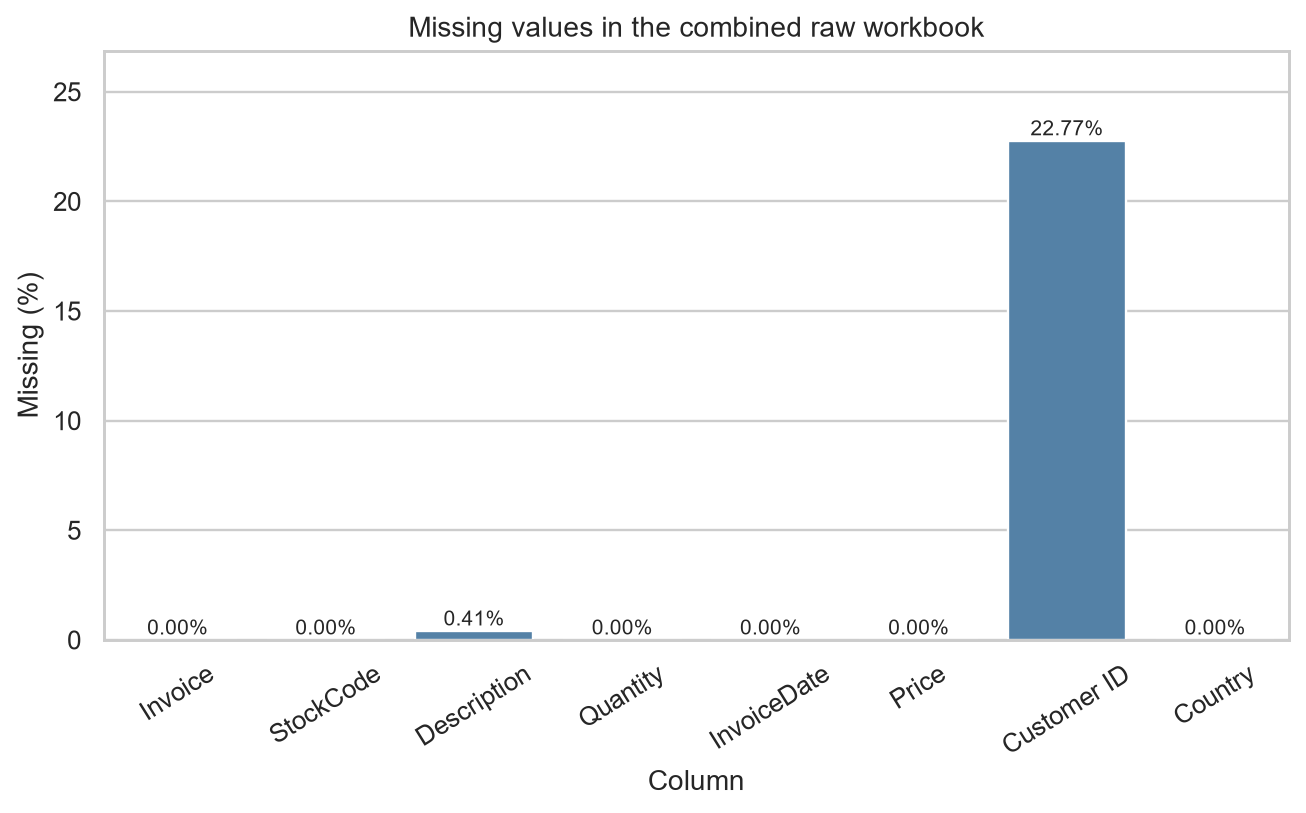

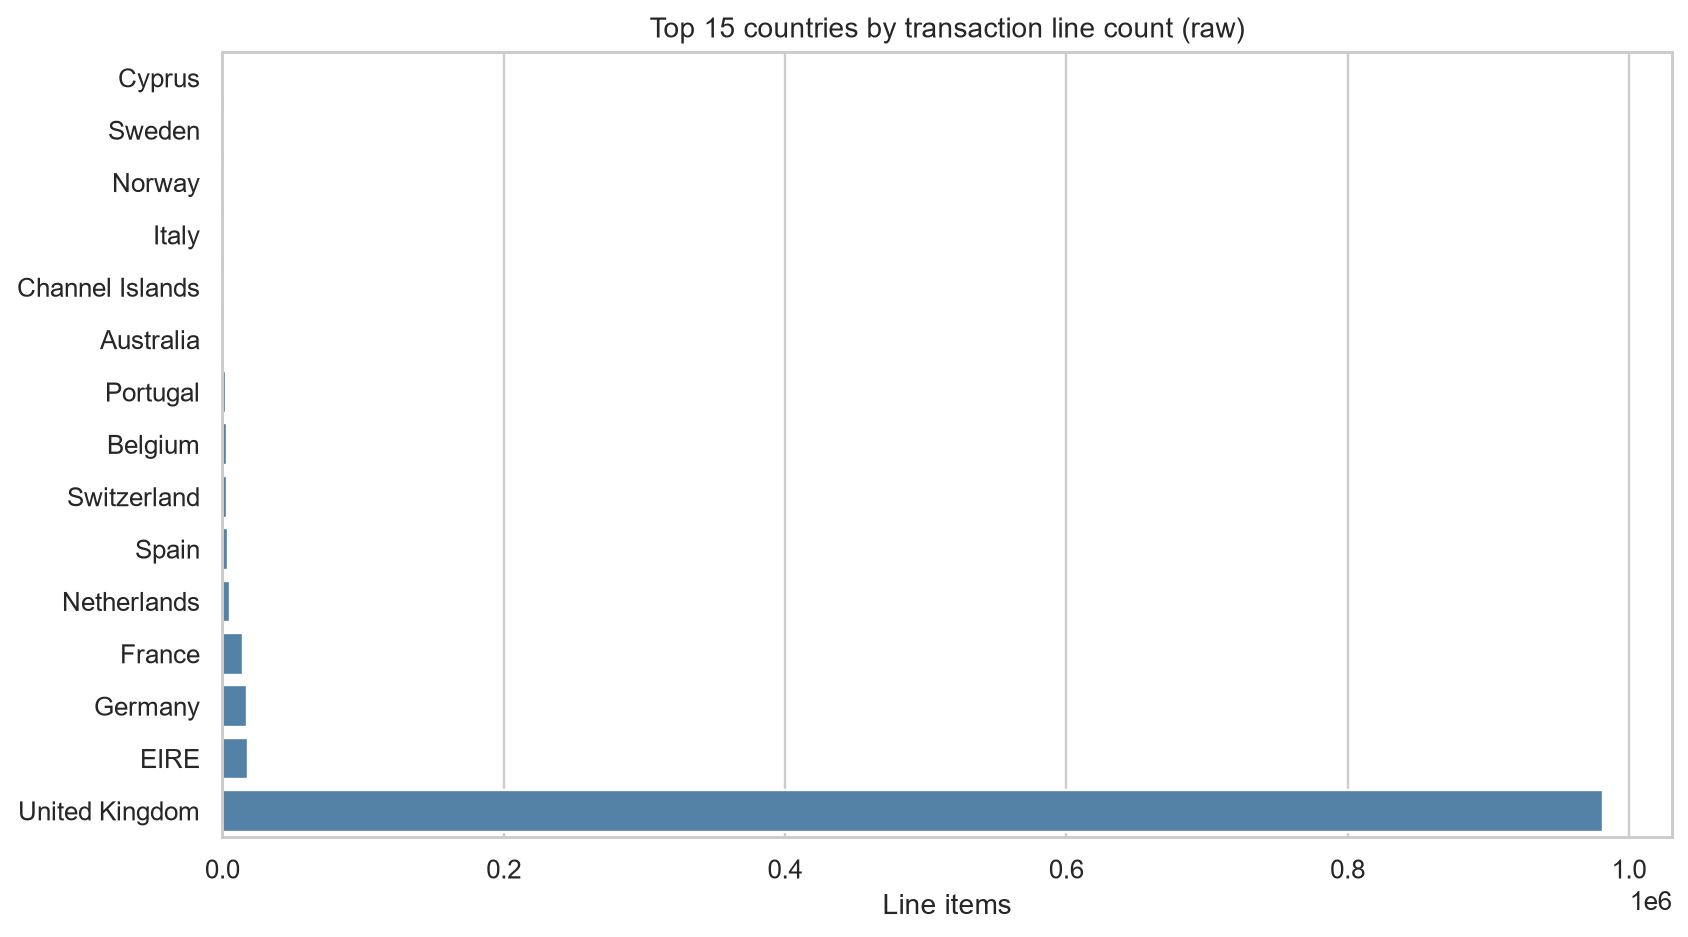

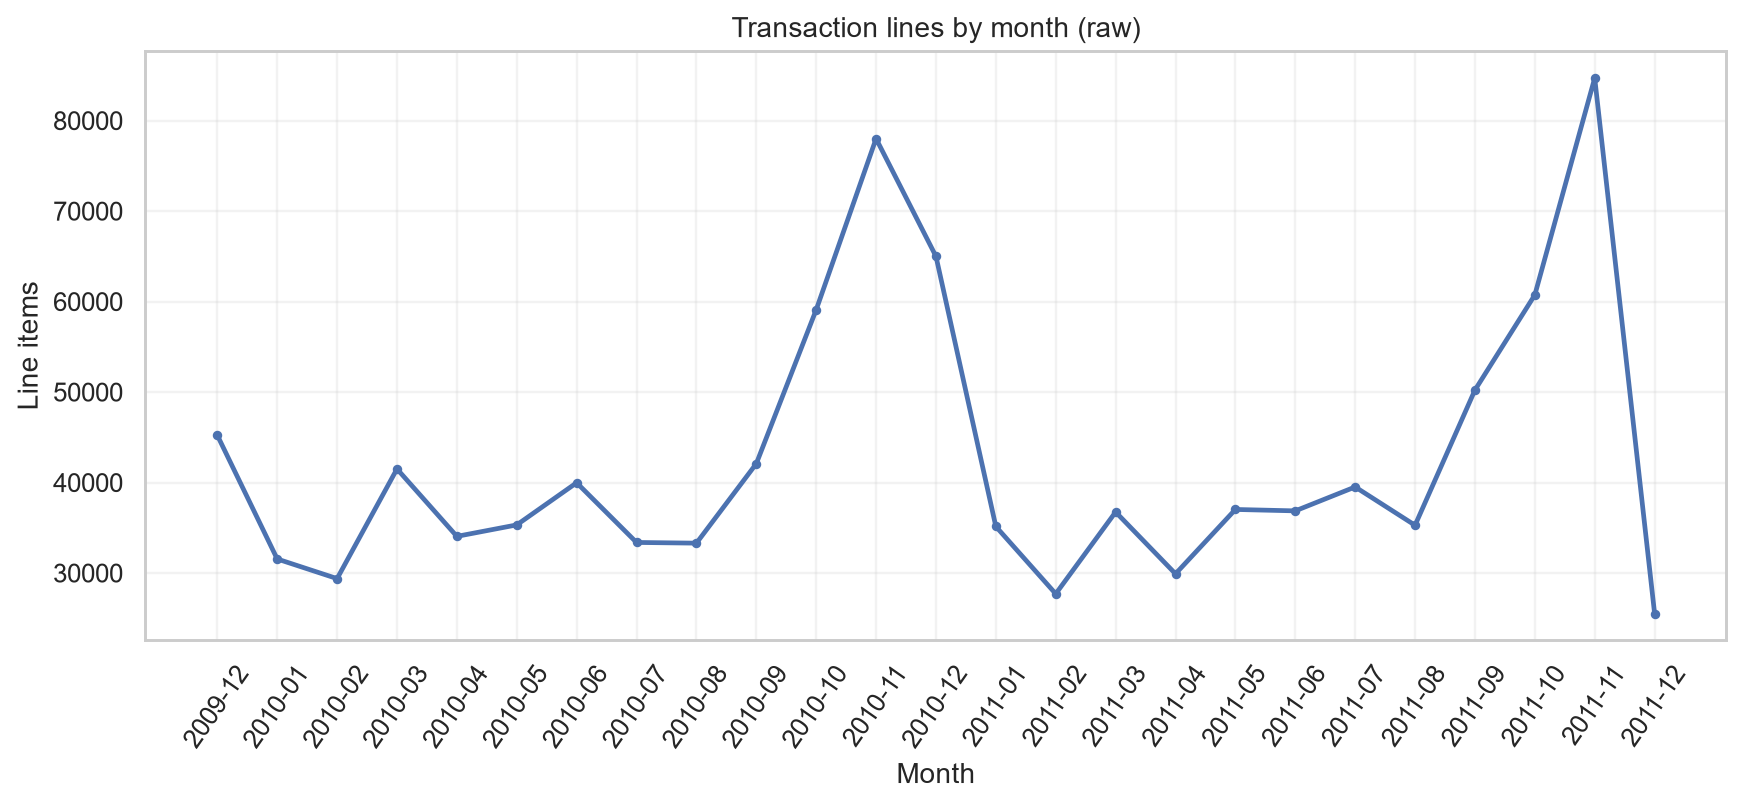

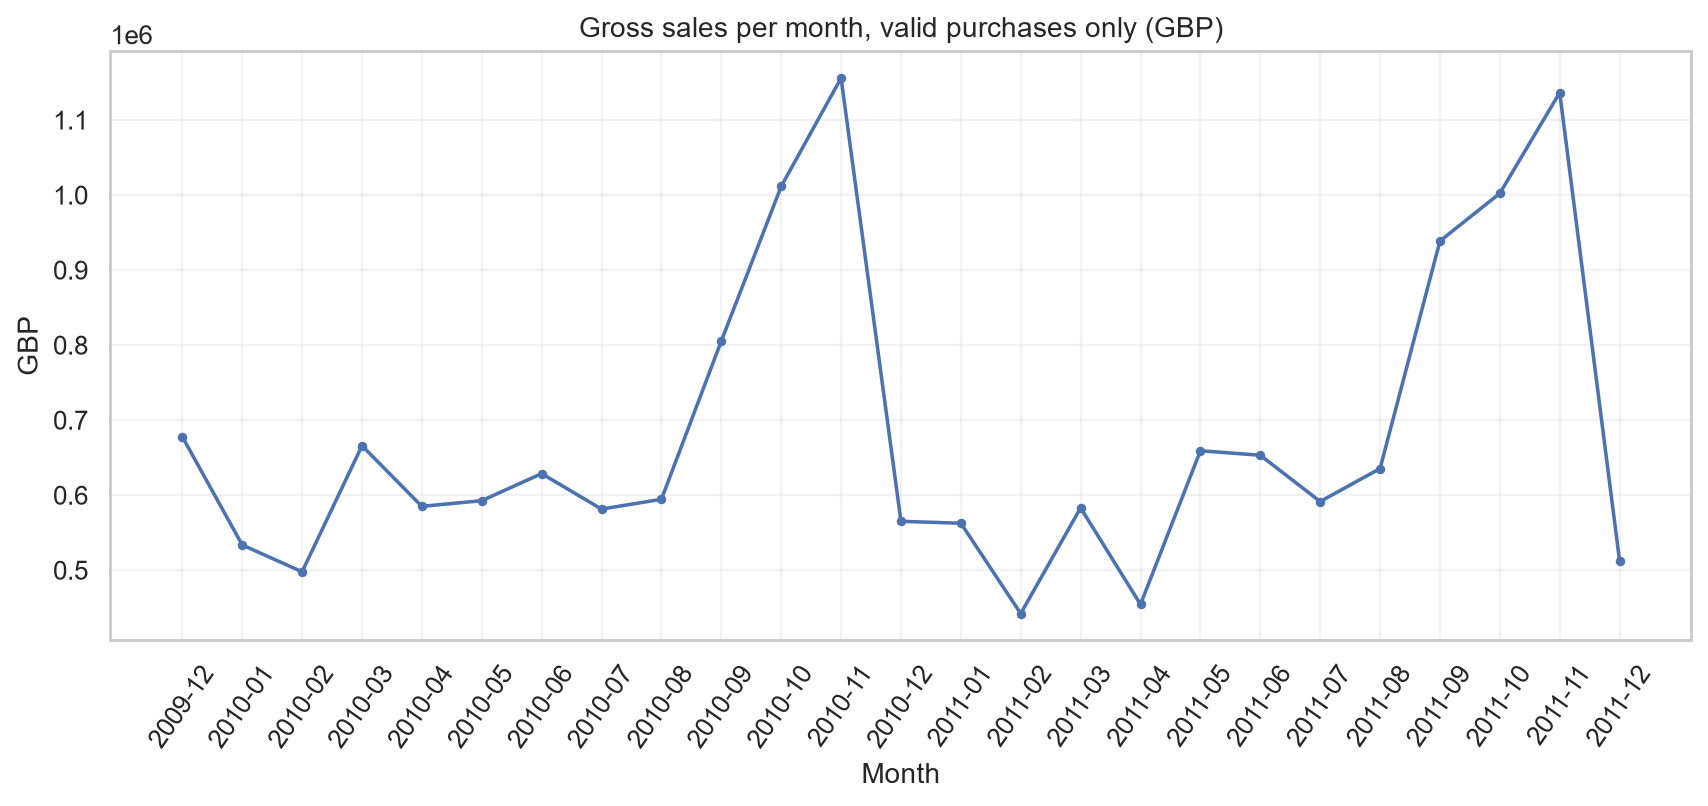

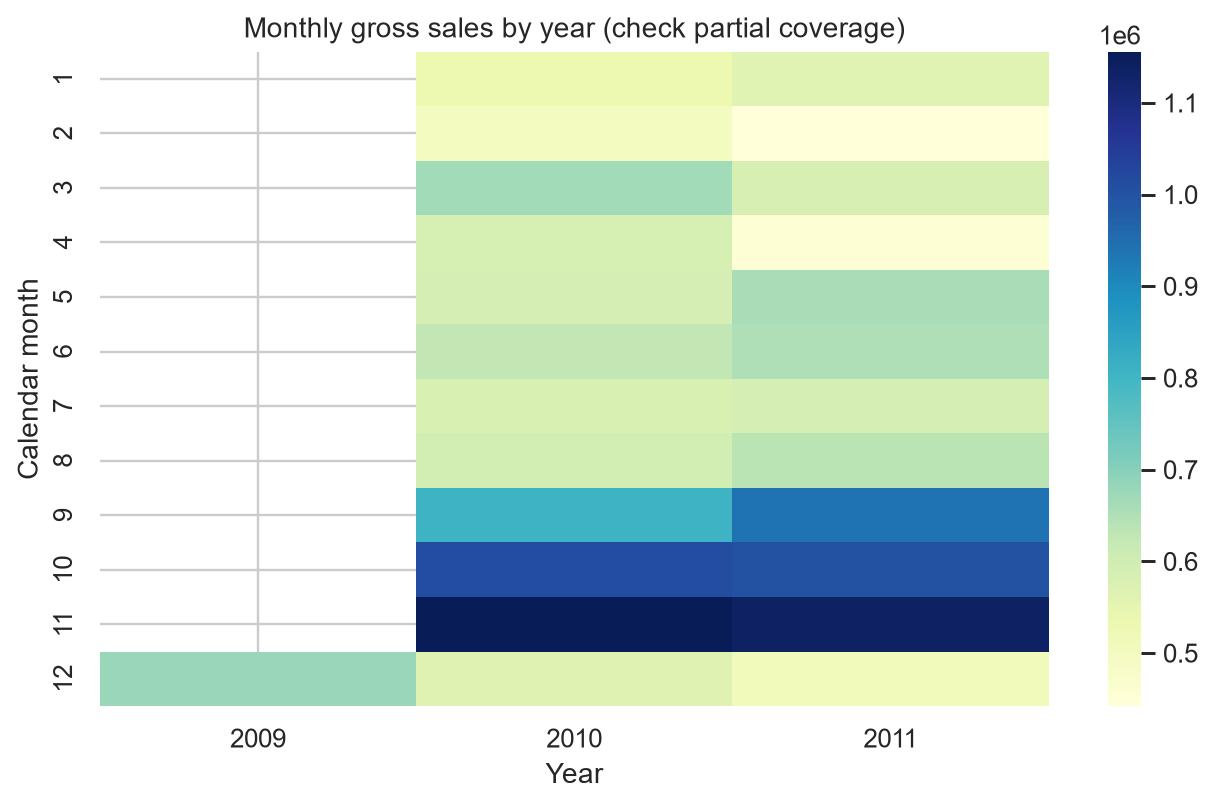

In [9]:
for name in (
    "01_missing_values.png", "02_countries.png", "03_monthly_raw.png",
    "04_monthly_clean_sales.png", "05_month_year_heatmap.png",
):
    display(Image(filename=str(ROOT / "preprocessing/figures" / name), width=820))


**Diễn giải mùa vụ:** đối chiếu lượng giao dịch theo thời gian và doanh số mua hợp lệ. Hai đầu chuỗi (tháng 12/2009 và 12/2011) không đủ tháng, nên không đánh giá riêng các tháng đó như đại diện cho mức mua của tháng 12. Biểu đồ không chứng minh nguyên nhân biến động.

## 10. Histogram và boxplot theo từng biến

### Recency

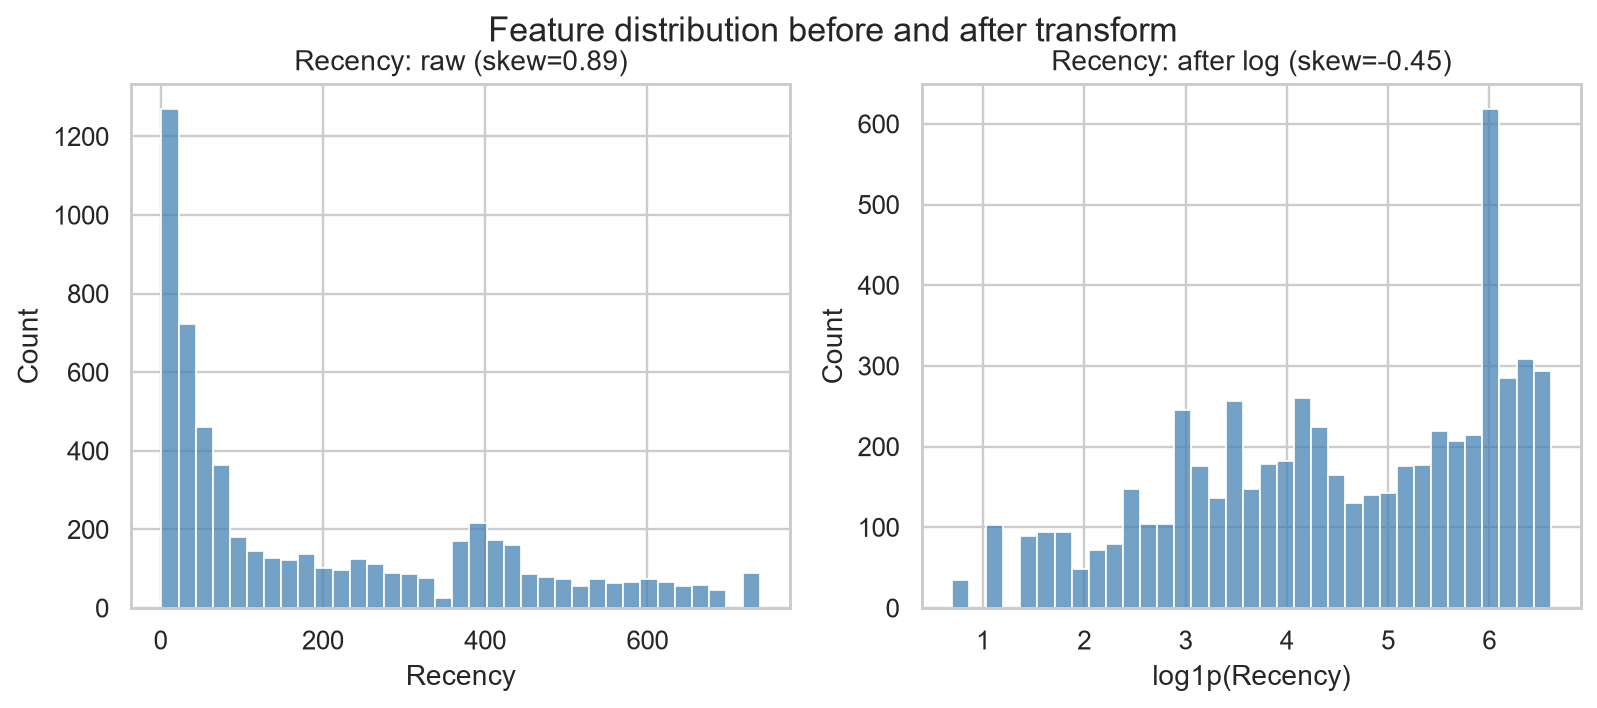

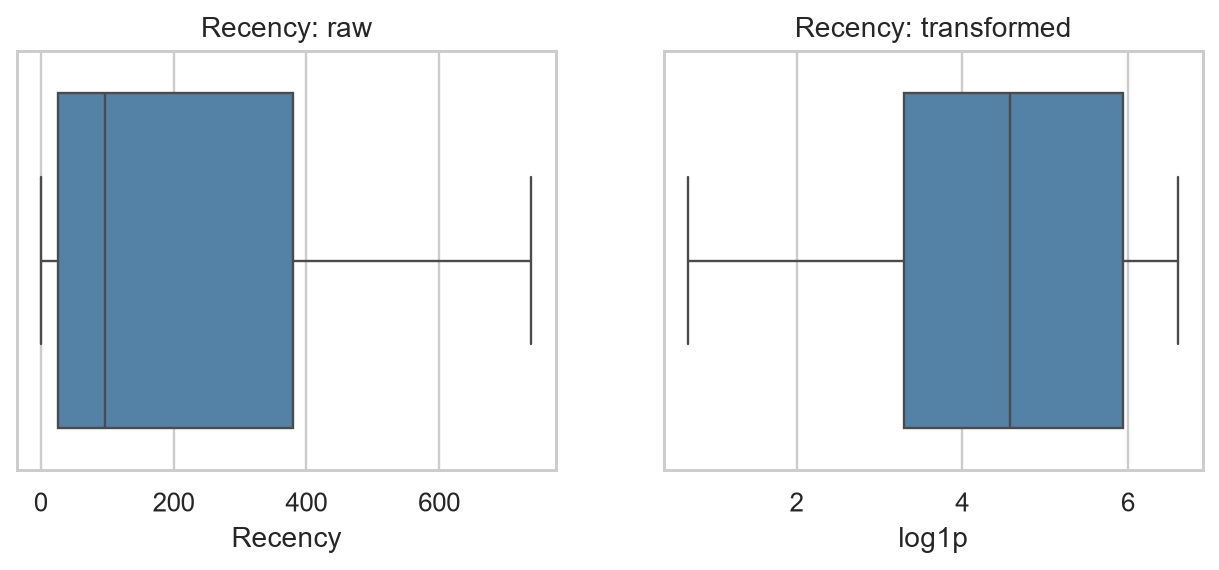

### Frequency

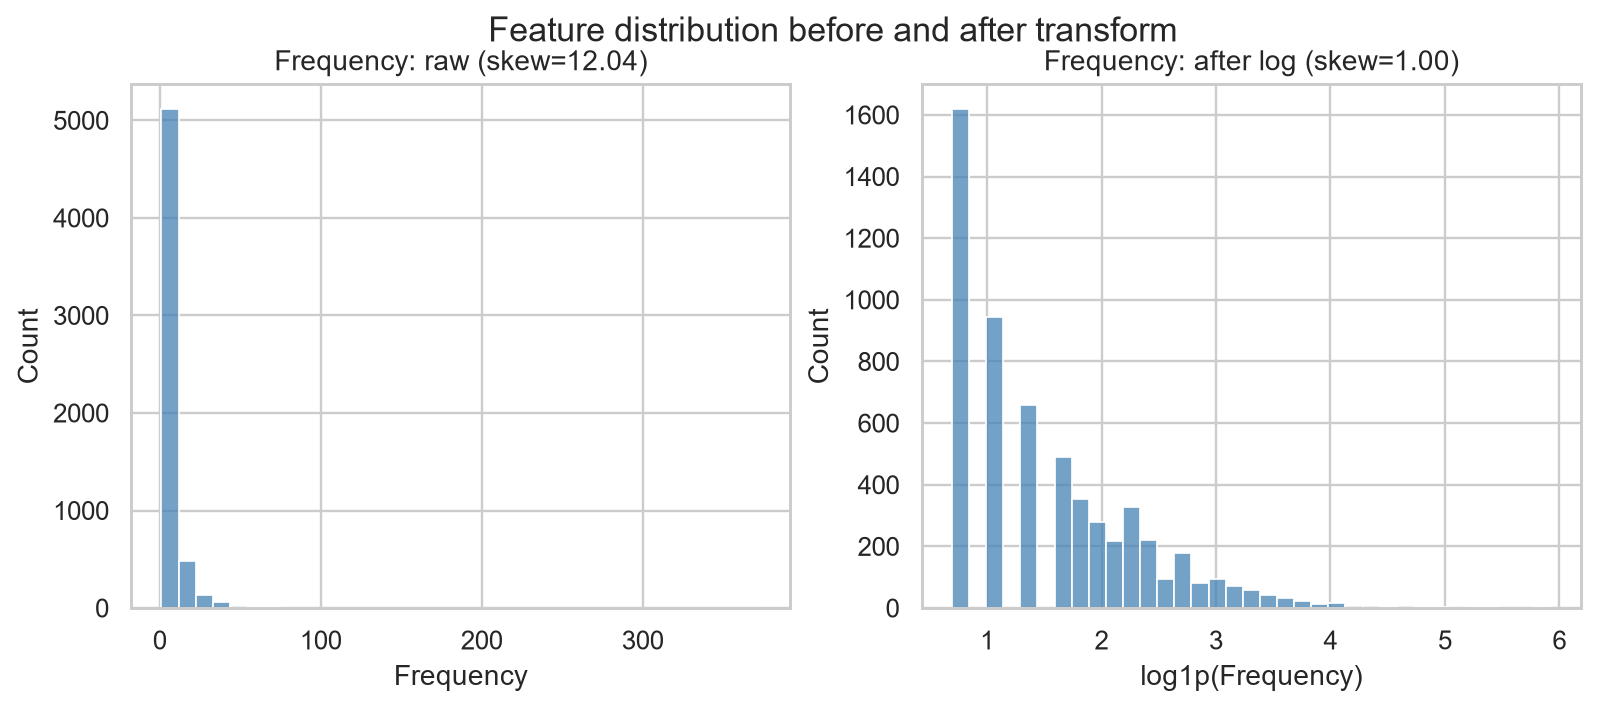

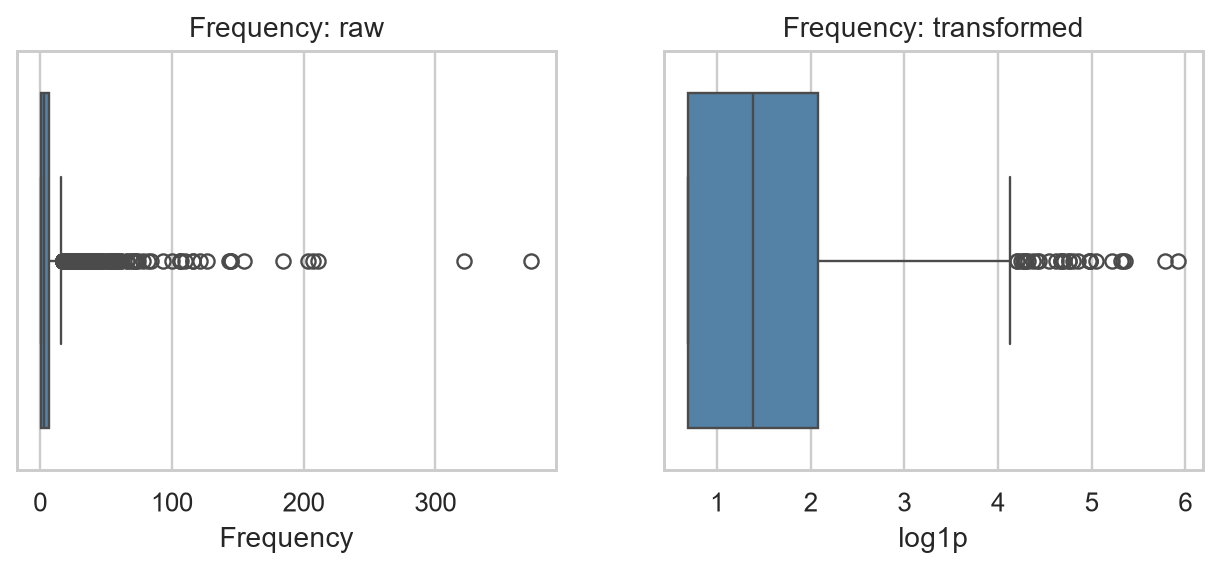

### Monetary

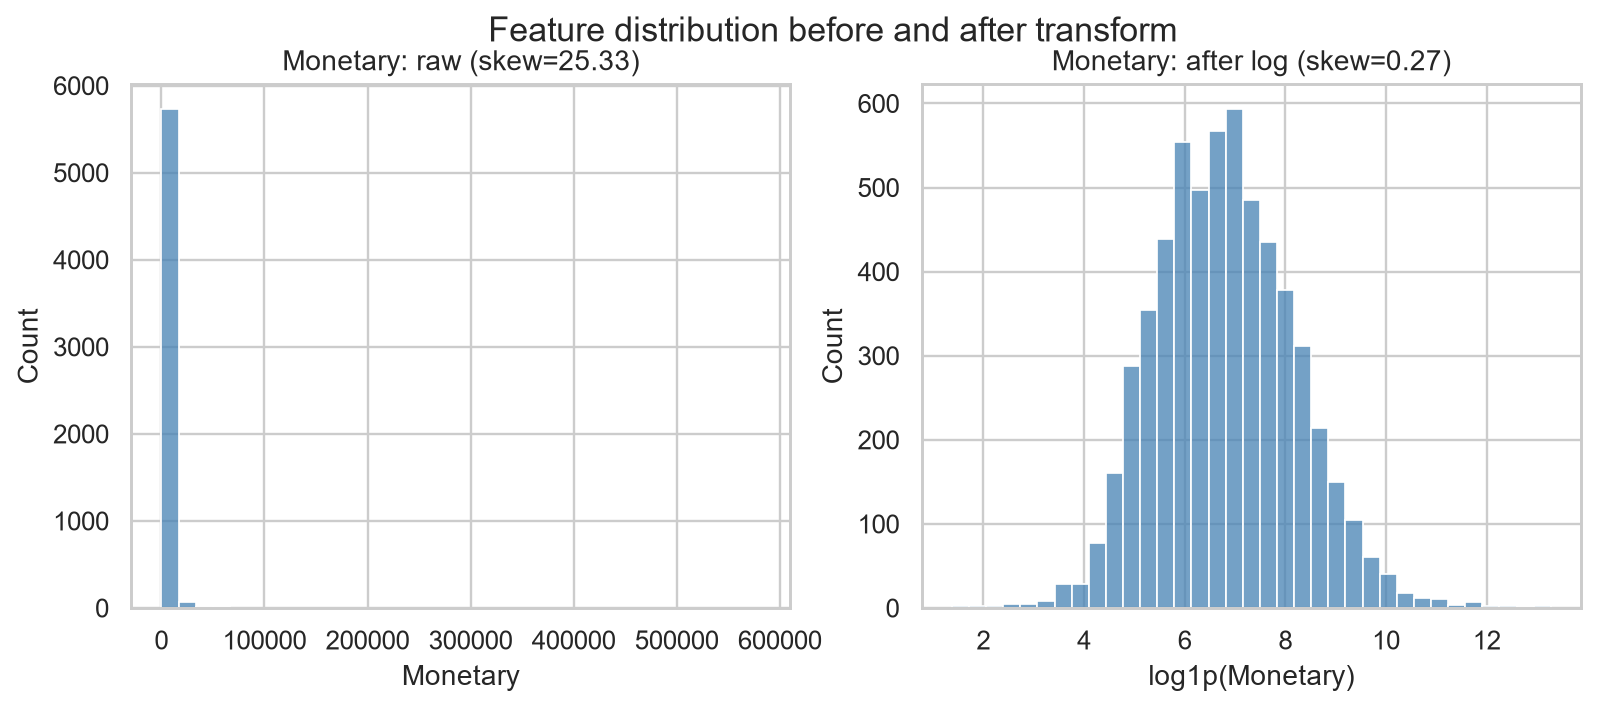

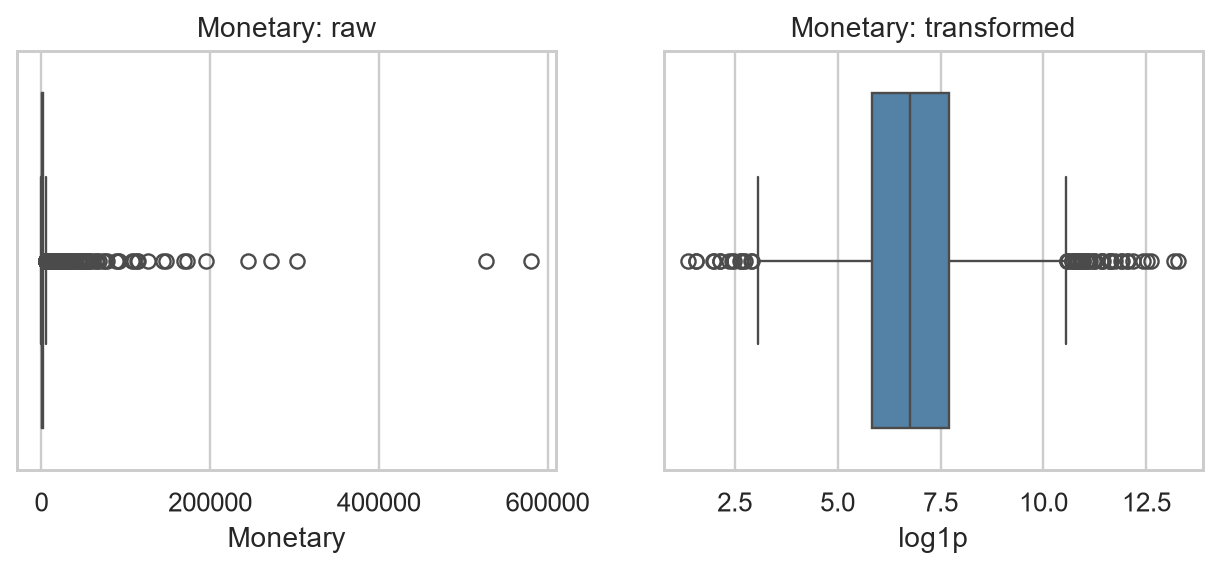

### AvgOrderValue

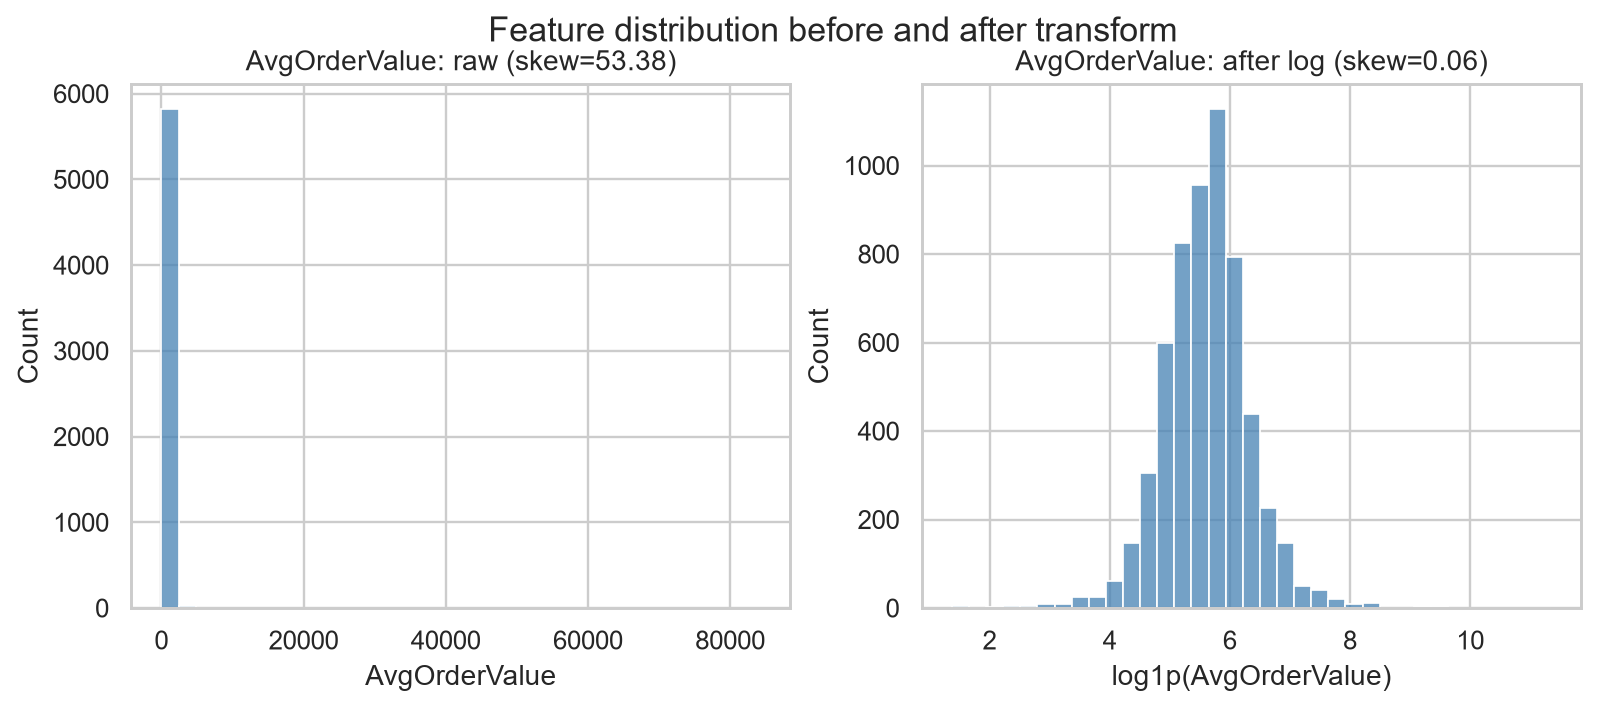

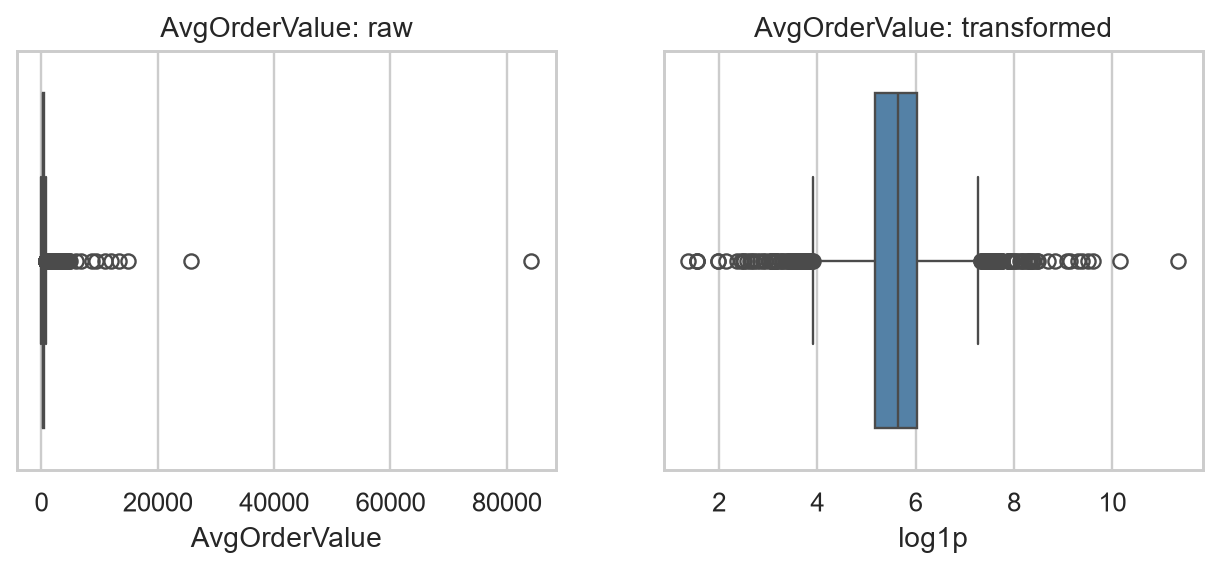

### UniqueProducts

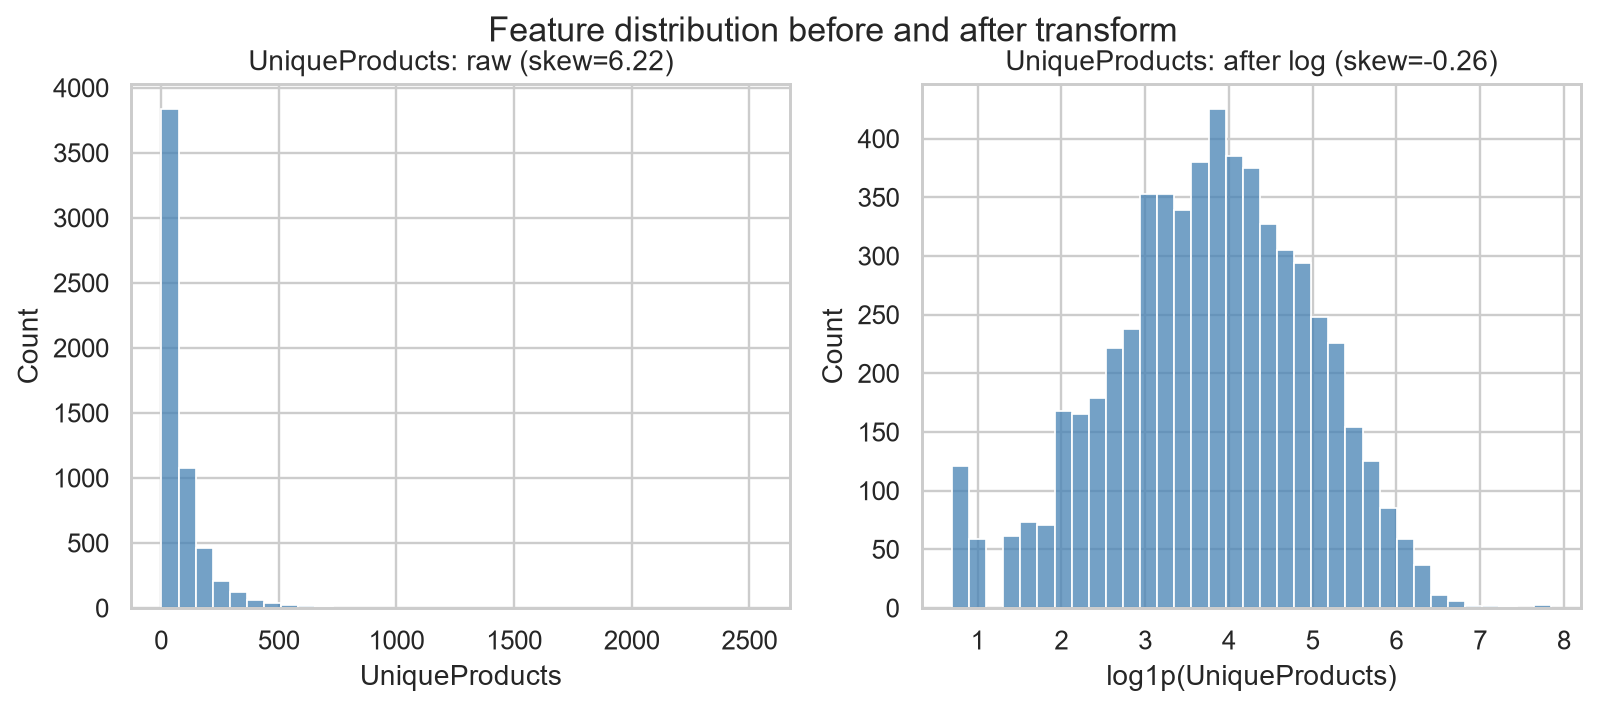

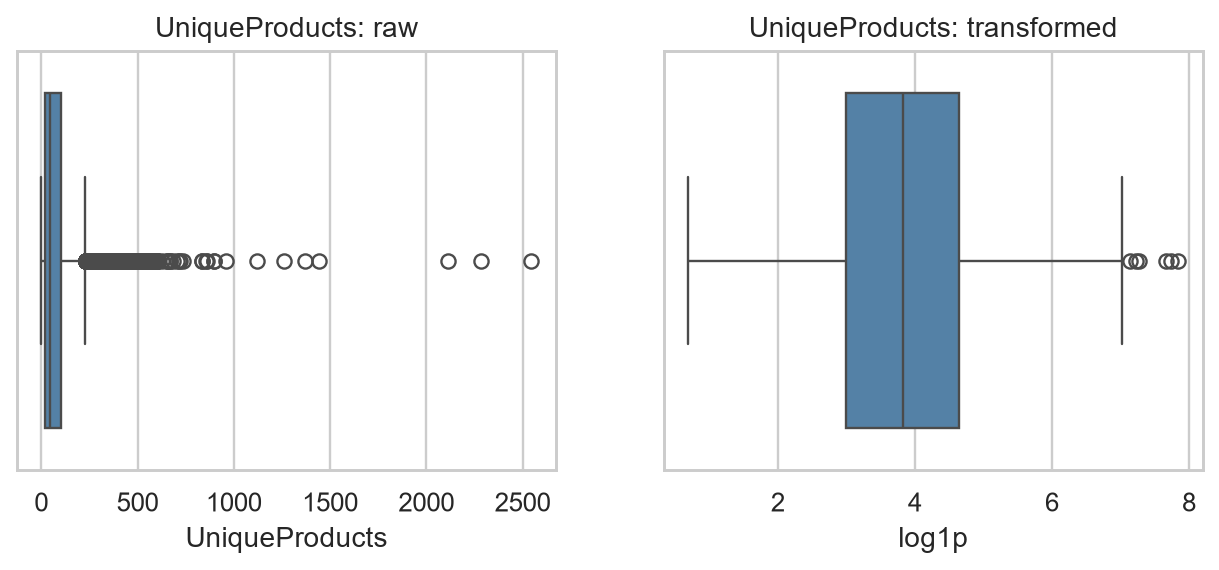

### AvgBasketSize

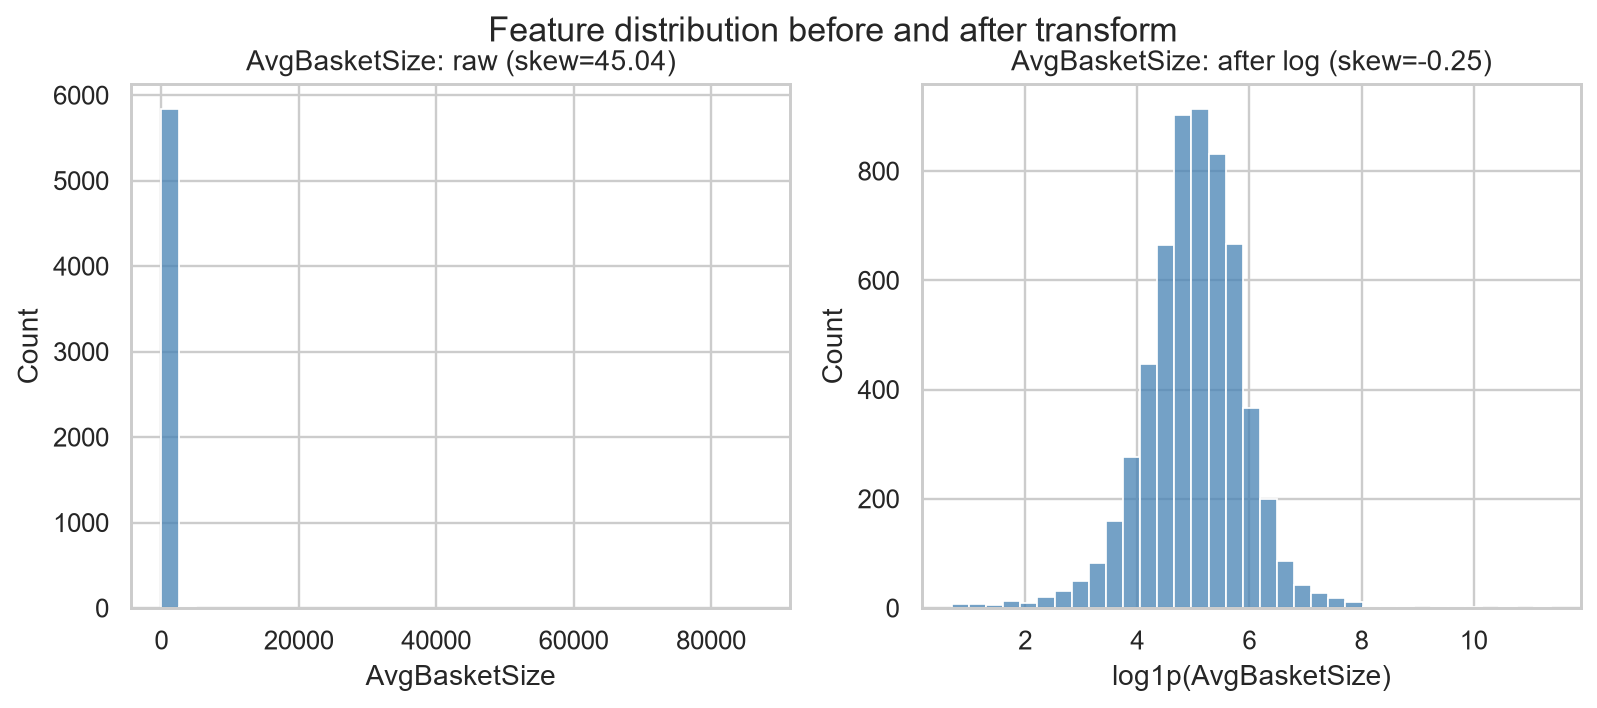

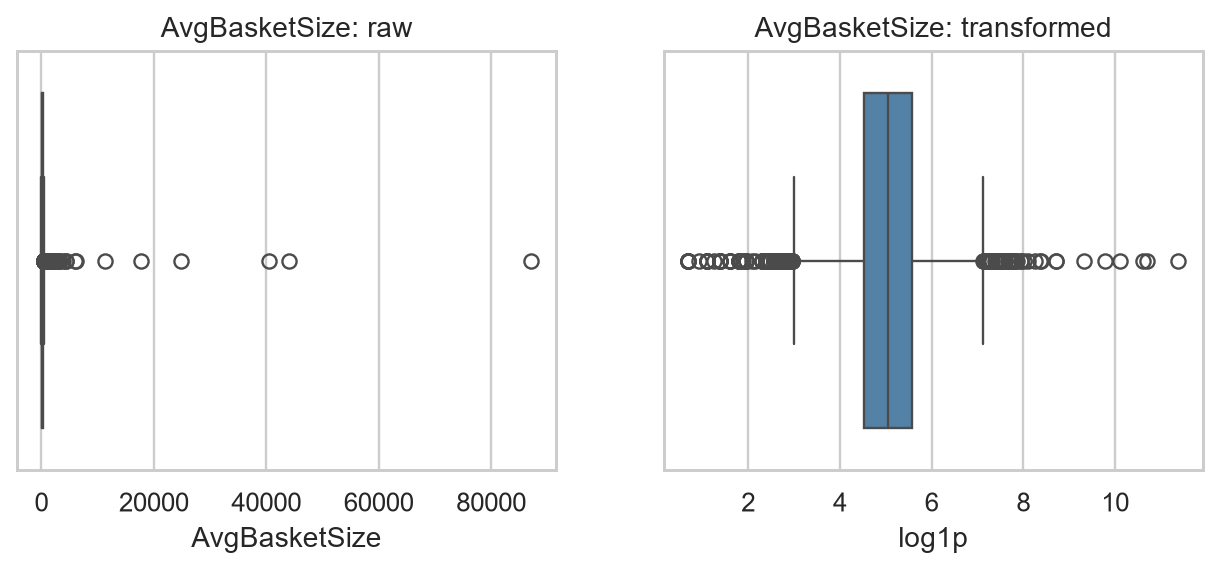

### Tenure

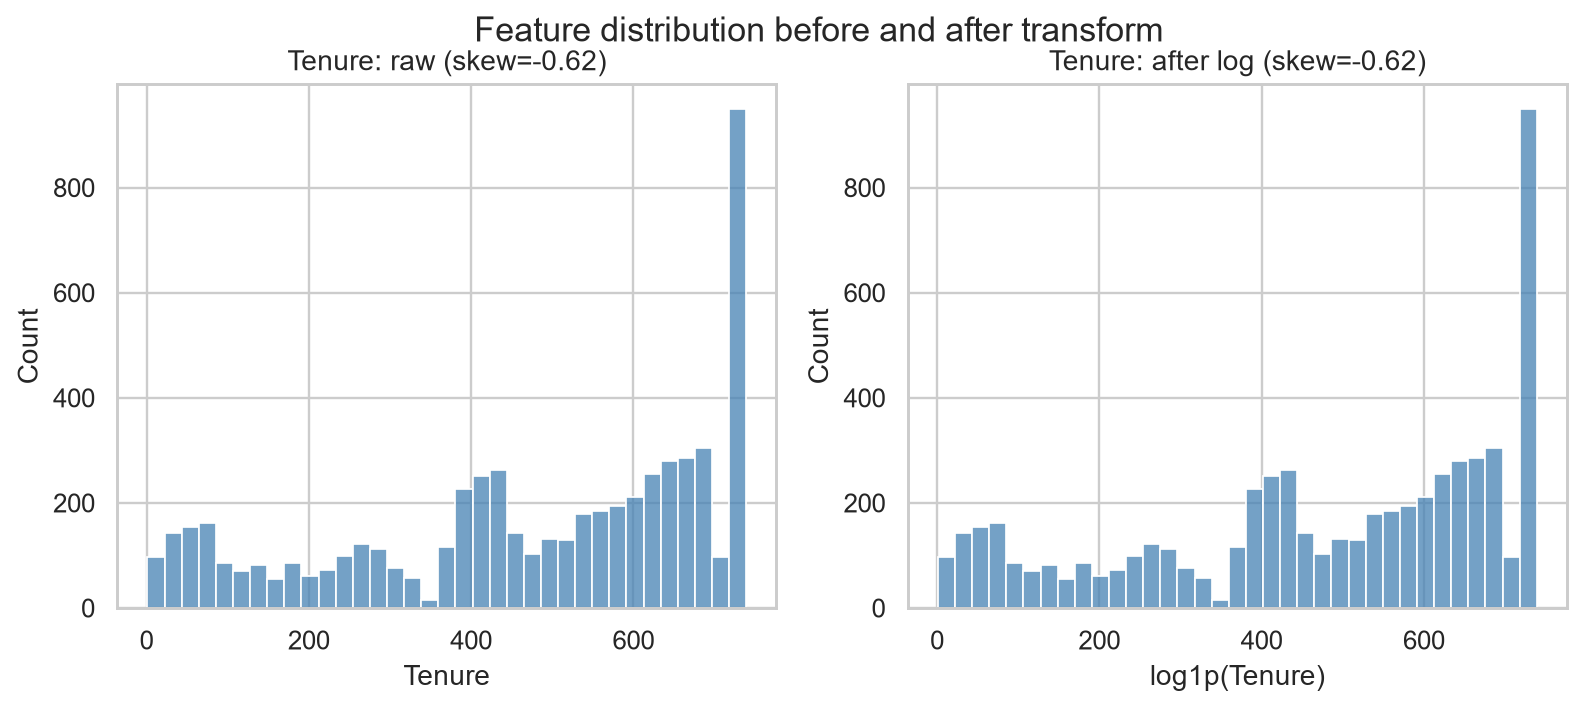

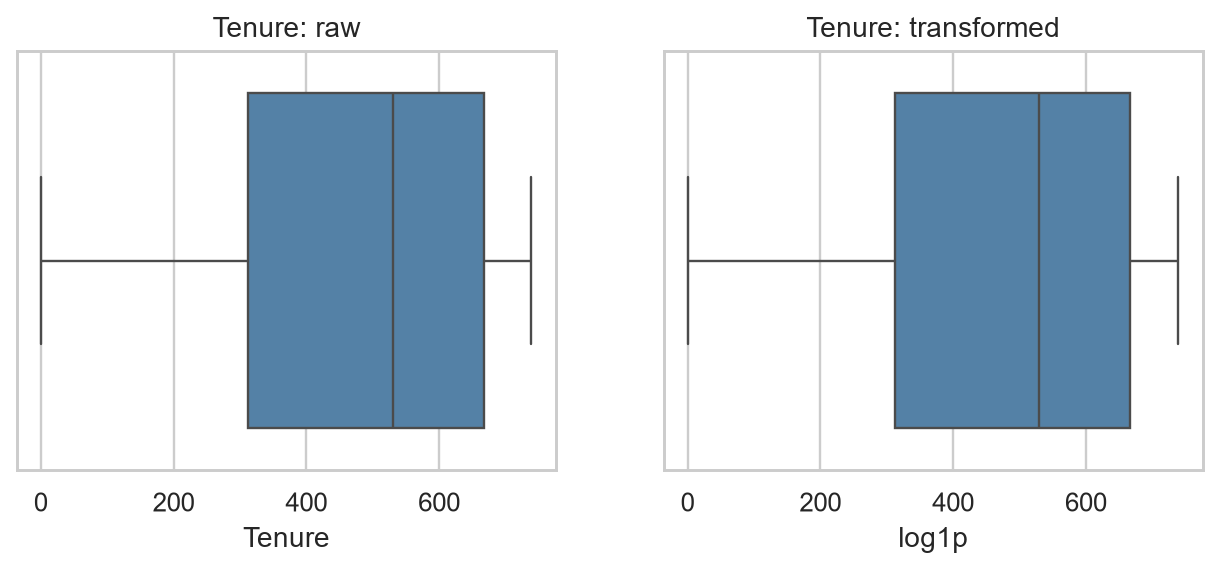

### CancelRate

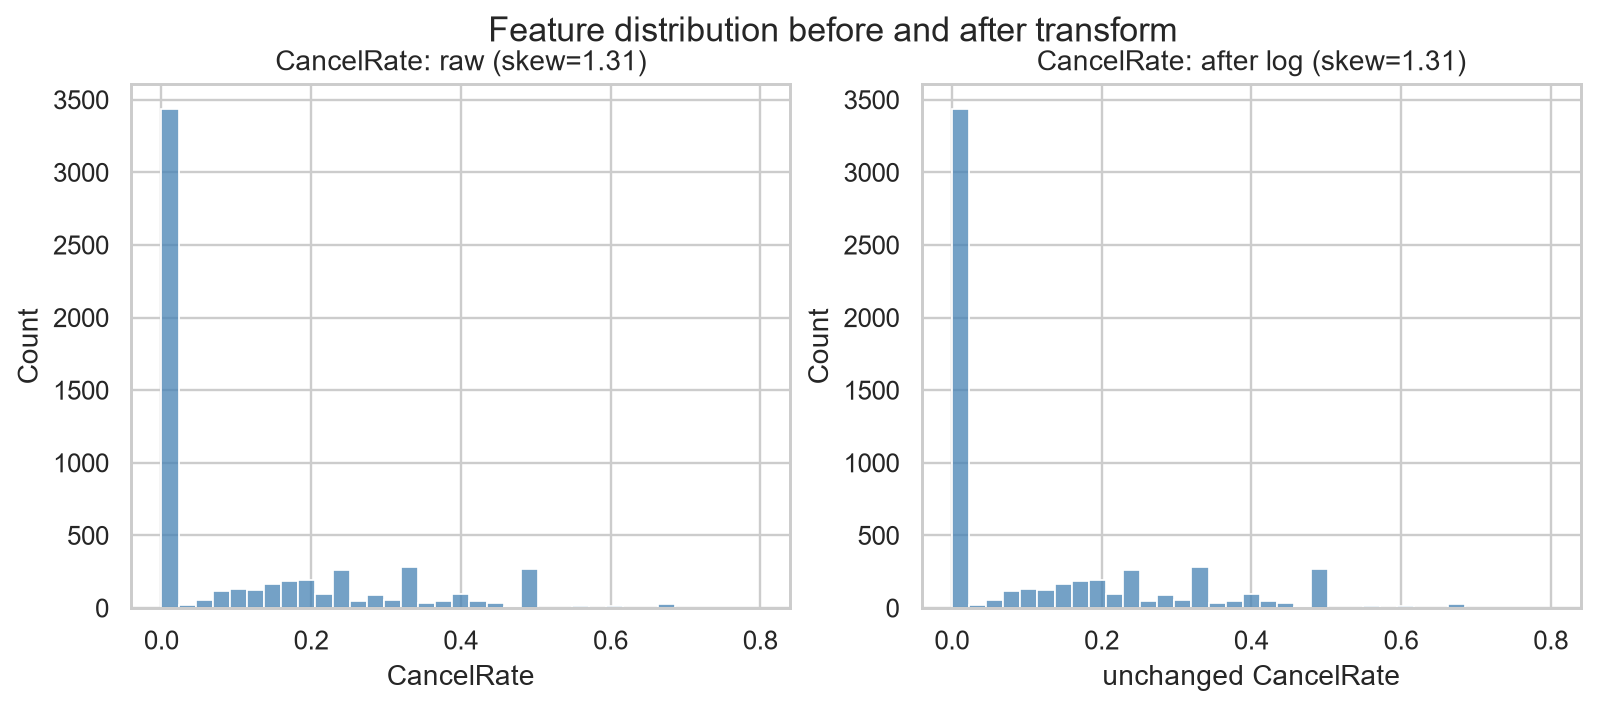

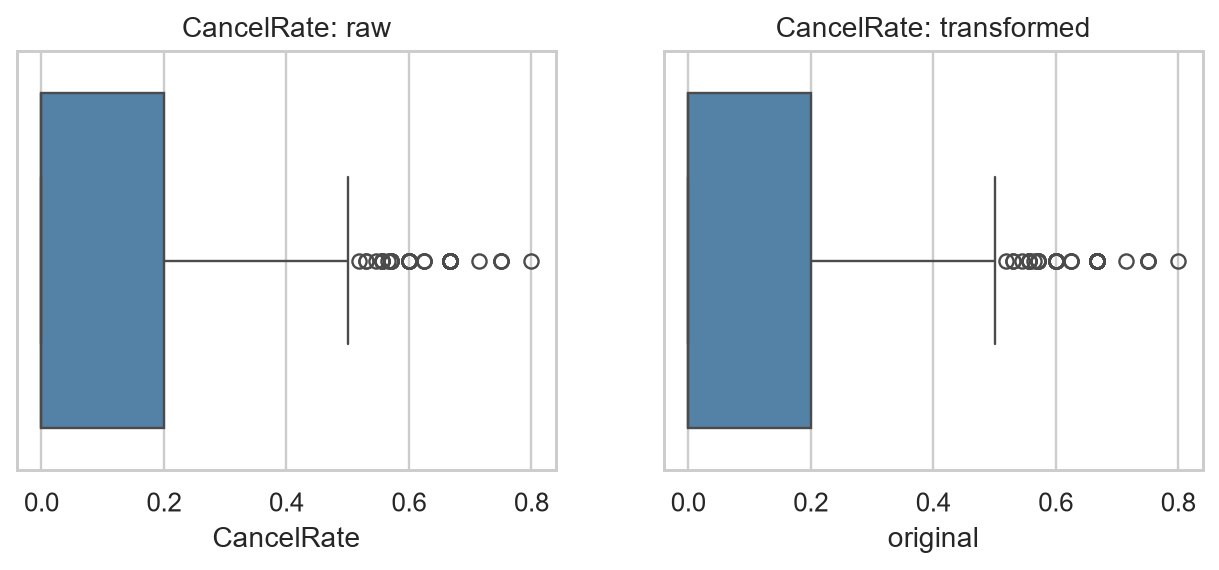

In [10]:
for i, name in enumerate(FEATURE_COLUMNS, start=1):
    display(Markdown(f"### {name}"))
    display(Image(filename=str(ROOT / "preprocessing/figures" / f"feature_{i:02d}_{name.lower()}_hist.png"), width=850))
    display(Image(filename=str(ROOT / "preprocessing/figures" / f"feature_{i:02d}_{name.lower()}_box.png"), width=750))


## 11. Ma trận tương quan, các cặp cần cân nhắc

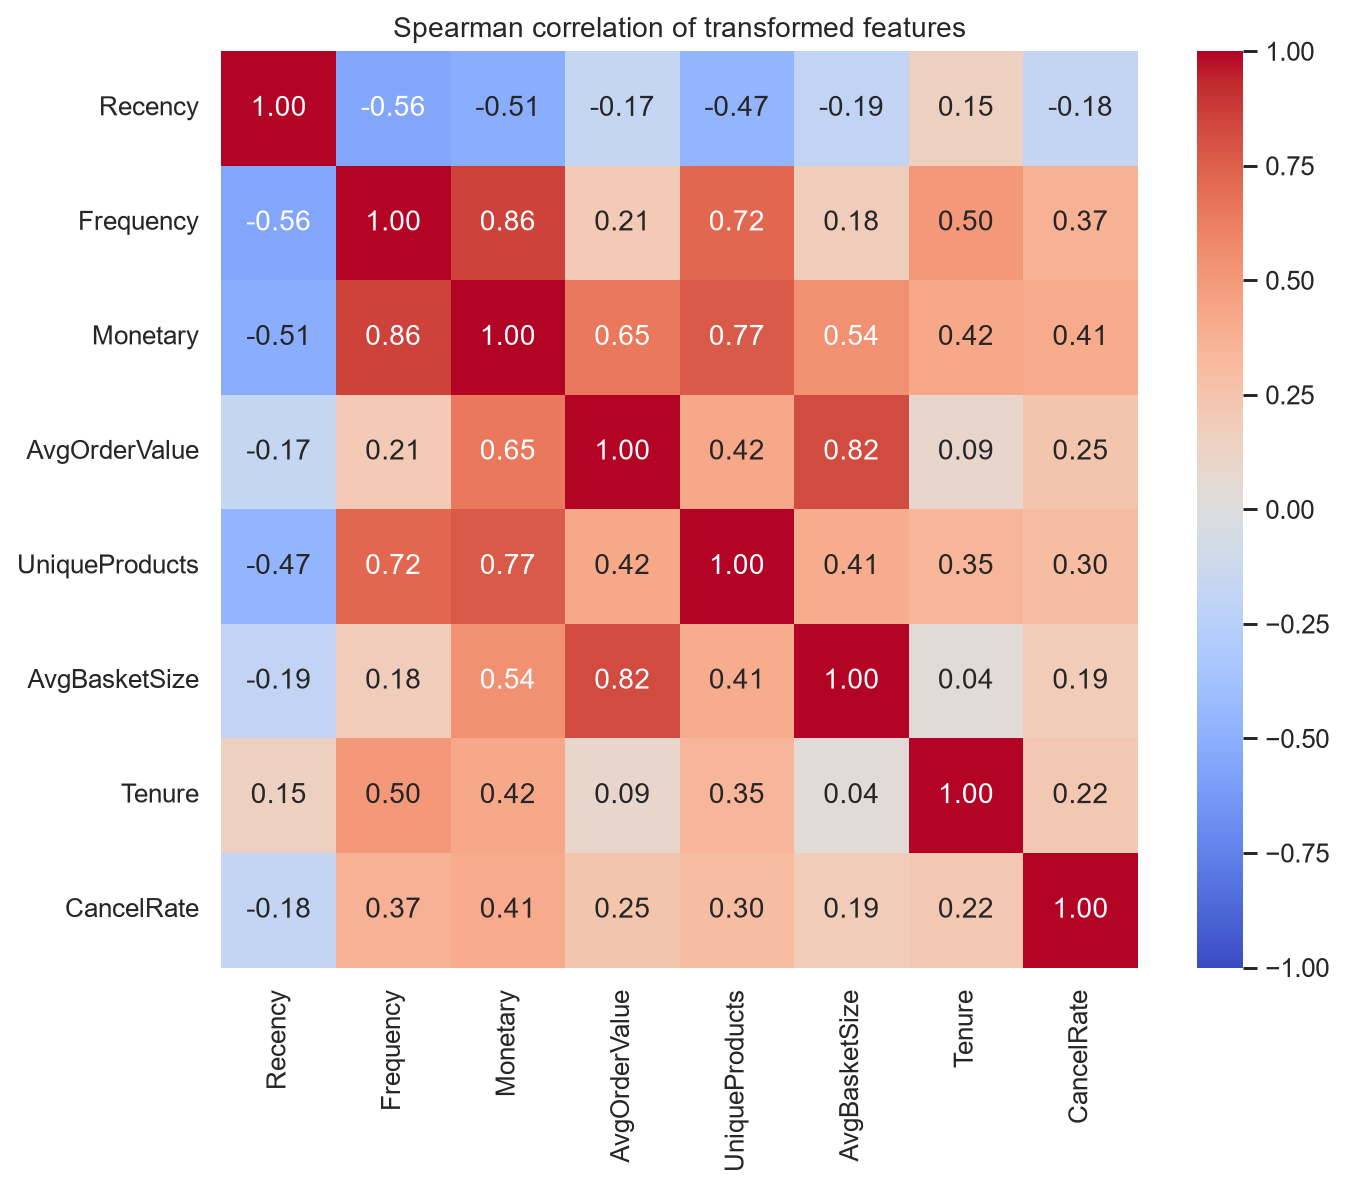

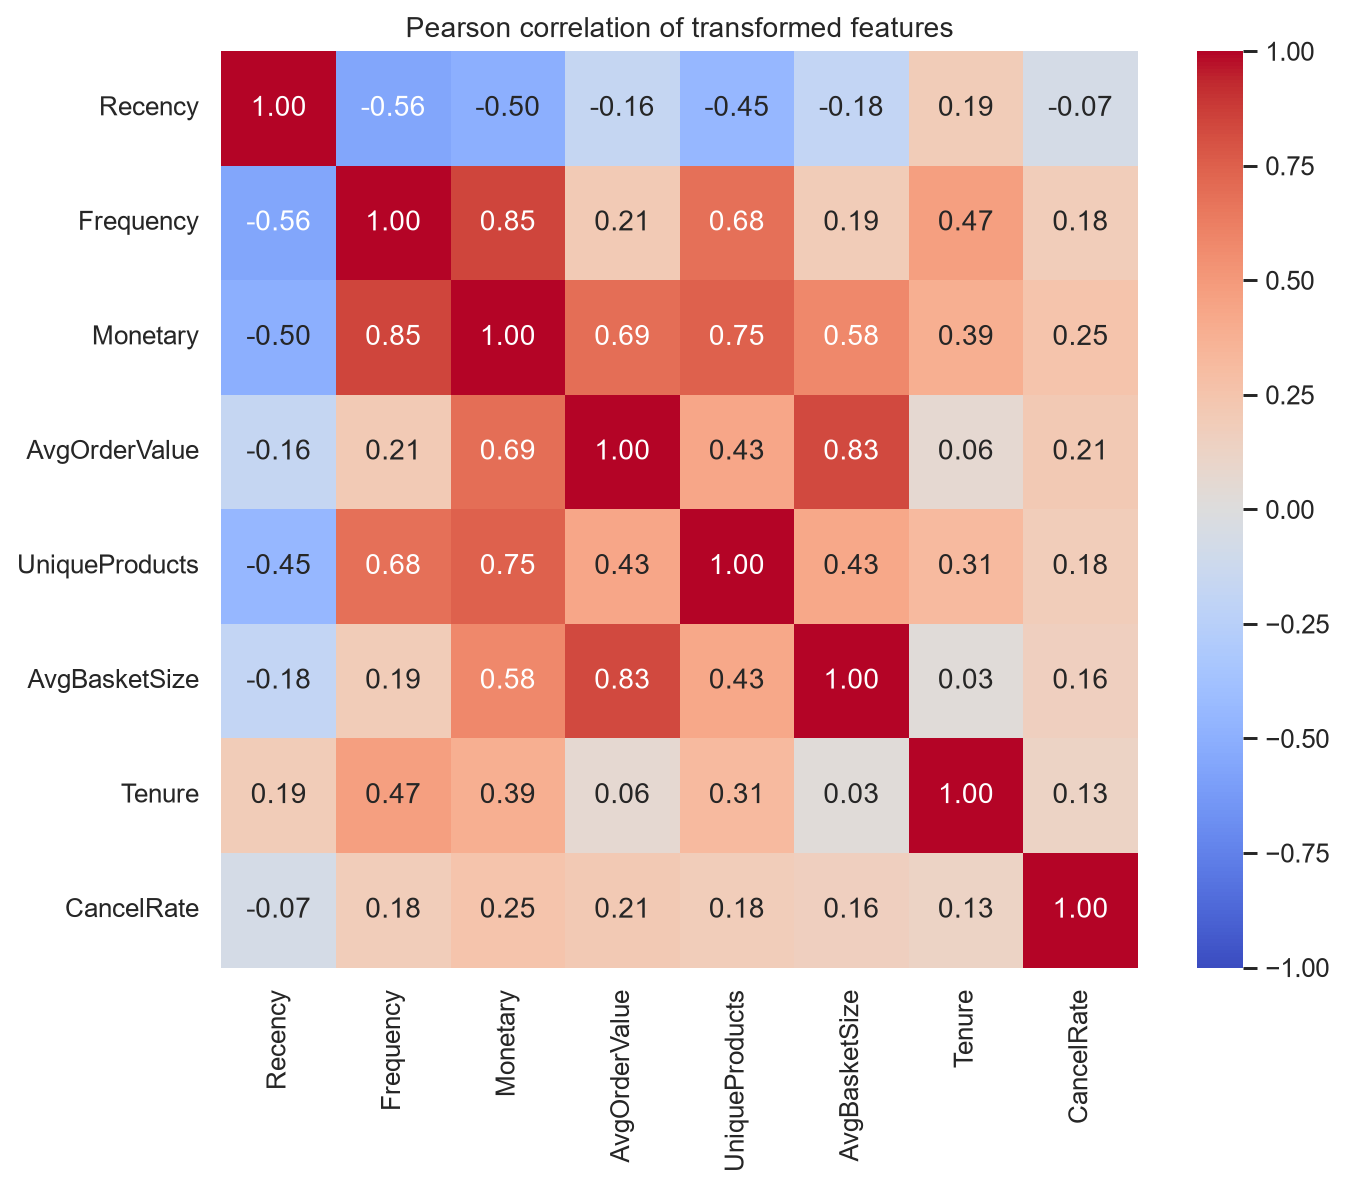

'Khong co cap |Spearman| >= 0.90'

In [11]:
display(Image(filename=str(ROOT / "preprocessing/figures/07_correlation_spearman.png"), width=800))
display(Image(filename=str(ROOT / "preprocessing/figures/07_correlation_pearson.png"), width=800))
high_pairs = find_high_correlations(features, threshold=0.90)
display(pd.DataFrame(high_pairs) if high_pairs else "Khong co cap |Spearman| >= 0.90")


**Quyết định:** Giữ nguyên tám đặc trưng bắt buộc để bàn giao nhất quán cho TV2/TV3. Nếu hai biến tương quan quá mạnh, nhóm mô hình có thể chạy ablation rồi thảo luận việc bỏ một biến; không tự động xóa trước khi so sánh mô hình.

## 12. Kiểm tra dữ liệu và scaler bàn giao

In [12]:
import joblib
import numpy as np
saved_features = pd.read_csv(ROOT / "data/processed/customers_features.csv", index_col="Customer ID")
saved_scaled = pd.read_csv(ROOT / "data/processed/X_scaled.csv", index_col="Customer ID")
saved_features.index = saved_features.index.astype(str)
saved_scaled.index = saved_scaled.index.astype(str)
saved_features.index.name = "Customer ID"
saved_scaled.index.name = "Customer ID"
loaded_scaler = joblib.load(ROOT / "models/scaler.joblib")
computed_scaled = transform_features(saved_features, loaded_scaler)
np.testing.assert_allclose(saved_scaled.to_numpy(), computed_scaled.to_numpy(), atol=1e-8, rtol=1e-8)
assert list(saved_features.columns) == list(saved_scaled.columns) == list(FEATURE_COLUMNS)
assert saved_features.index.equals(saved_scaled.index)
print("PASS: 8 cot, cung index, khong NaN/Inf va scaler sau khi load cho ket qua nhat quan.")


PASS: 8 cot, cung index, khong NaN/Inf va scaler sau khi load cho ket qua nhat quan.


### Tệp và giới hạn

Kết quả xuất ra `data/processed/` và `models/` **không commit** (theo README của nhóm). Gửi tệp này qua Drive nhóm. Notebook và mã nguồn có thể đưa vào nhánh `feature/preprocessing`. Dữ liệu UCI gốc phải được tải từ nguồn chính thức và không thay bằng kết quả chạy thử từ unit test.